# Predicción de churn de clientes con PySpark

**Proyecto final · Máster en Big Data y Análisis de Datos (Tokio School)**
Roberto Peña Alcaide

**Escenario.** Tras conseguir el primer trabajo como analista de datos en la empresa ficticia *Tokio Telecom*, el objetivo es analizar
un conjunto de datos de clientes de telefonía móvil y su baja del servicio (*churn*), y construir un modelo que prediga qué clientes
tienen más probabilidad de abandonar la compañía.

**Dataset:** `data/customer_churn_10k.csv` (10.000 clientes, 12 columnas).

**Contenido**
1. Análisis inicial
2. Análisis descriptivo
3. Análisis de correlación
4. Machine Learning: Random Forest vs Árbol de Decisión
5. Prueba de robustez sin la variable `Contract Length`
6. Segmentación por nivel de riesgo y exportación a Power BI
7. Importancia de las variables y conclusiones

## Librerías y configuración

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_curve, auc

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import RandomForestClassifier, DecisionTreeClassifier
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.evaluation import BinaryClassificationEvaluator

# Rutas relativas a la raíz del repositorio (el notebook vive en notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "customer_churn_10k.csv"
IMG_DIR = ROOT / "images"
OUTPUT_DIR = ROOT / "output"
IMG_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

# Estilo de las gráficas
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e6e5e0",
    "axes.axisbelow": True,
})

def save_fig(name):
    plt.savefig(IMG_DIR / name, dpi=200, bbox_inches="tight")

## Carga de los datos de Tokio Telecom

In [2]:
spark = (SparkSession.builder
         .appName("ChurnAnalysis")
         .master("local[*]")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

df = spark.read.csv(str(DATA_PATH), header=True, inferSchema=True)

# 1. Análisis inicial de los datos
Se analiza la estructura del archivo: tipos de cada columna, una vista previa, el número de registros y si hay valores nulos.

In [3]:
df.printSchema()
df.show(5)
print("Número de clientes:", df.count())

root
 |-- CustomerID: double (nullable = true)
 |-- Age: double (nullable = true)
 |-- Gender: string (nullable = true)
 |-- Tenure: double (nullable = true)
 |-- Usage Frequency: double (nullable = true)
 |-- Support Calls: double (nullable = true)
 |-- Payment Delay: double (nullable = true)
 |-- Subscription Type: string (nullable = true)
 |-- Contract Length: string (nullable = true)
 |-- Total Spend: double (nullable = true)
 |-- Last Interaction: double (nullable = true)
 |-- Churn_YesNo: string (nullable = true)



+----------+----+------+------+---------------+-------------+-------------+-----------------+---------------+-----------+----------------+-----------+
|CustomerID| Age|Gender|Tenure|Usage Frequency|Support Calls|Payment Delay|Subscription Type|Contract Length|Total Spend|Last Interaction|Churn_YesNo|
+----------+----+------+------+---------------+-------------+-------------+-----------------+---------------+-----------+----------------+-----------+
|  314921.0|36.0|  Male|  10.0|           14.0|          1.0|         20.0|         Standard|         Annual|     736.02|            27.0|         No|
|  401716.0|40.0|  Male|  20.0|           23.0|          4.0|          6.0|         Standard|      Quarterly|      897.3|            29.0|         No|
|   99832.0|36.0|Female|  52.0|           23.0|          1.0|          0.0|         Standard|      Quarterly|      697.0|            29.0|        Yes|
|  168747.0|65.0|  Male|  55.0|            3.0|         10.0|         14.0|            Basic| 

Número de clientes: 10000


In [4]:
# Comprobación de valores nulos por columna
df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).show()

+----------+---+------+------+---------------+-------------+-------------+-----------------+---------------+-----------+----------------+-----------+
|CustomerID|Age|Gender|Tenure|Usage Frequency|Support Calls|Payment Delay|Subscription Type|Contract Length|Total Spend|Last Interaction|Churn_YesNo|
+----------+---+------+------+---------------+-------------+-------------+-----------------+---------------+-----------+----------------+-----------+
|         0|  0|     0|     0|              0|            0|            0|                0|              0|          0|               0|          0|
+----------+---+------+------+---------------+-------------+-------------+-----------------+---------------+-----------+----------------+-----------+



In [5]:
# Tasa de churn global
df.groupBy("Churn_YesNo").count().withColumn(
    "porcentaje", F.round(F.col("count") / df.count() * 100, 1)
).show()

+-----------+-----+----------+
|Churn_YesNo|count|porcentaje|
+-----------+-----+----------+
|         No| 4328|      43.3|
|        Yes| 5672|      56.7|
+-----------+-----+----------+



No hay valores nulos. La tasa de churn global es del **56,7 %**: más de la mitad de los clientes del dataset se ha dado de baja.
Es una proporción mucho más alta que la de una operadora real (normalmente por debajo del 30 % anual), lo que ya indica que se trata
de un dataset **sintético** y conviene tenerlo en cuenta al interpretar los resultados.

### Churn por tipo de tarifa

In [6]:
def churn_por(columna):
    return (df.groupBy(columna)
              .agg(F.count("*").alias("total_clientes"),
                   F.sum(F.when(F.col("Churn_YesNo") == "Yes", 1).otherwise(0)).alias("churn_yes"))
              .withColumn("churn_rate", F.round(F.col("churn_yes") / F.col("total_clientes"), 4))
              .orderBy(columna))

churn_por_tarifa = churn_por("Subscription Type")
churn_por_tarifa.show()

+-----------------+--------------+---------+----------+
|Subscription Type|total_clientes|churn_yes|churn_rate|
+-----------------+--------------+---------+----------+
|            Basic|          3233|     1884|    0.5827|
|          Premium|          3406|     1883|    0.5528|
|         Standard|          3361|     1905|    0.5668|
+-----------------+--------------+---------+----------+



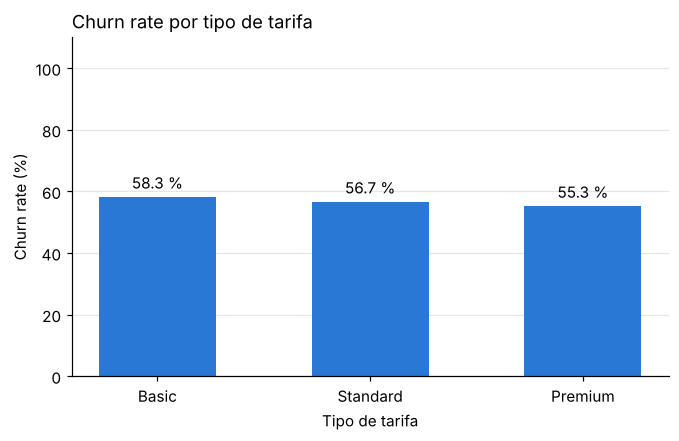

In [7]:
def barras_churn(pdf, columna, titulo, xlabel, fichero, orden=None):
    if orden:
        pdf = pdf.set_index(columna).loc[orden].reset_index()
    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.bar(pdf[columna], pdf["churn_rate"] * 100, color=BLUE, width=0.55)
    ax.bar_label(bars, labels=[f"{v:.1f} %" for v in pdf["churn_rate"] * 100], padding=3)
    ax.set_ylim(0, 110)
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel(xlabel)
    ax.set_title(titulo, loc="left")
    save_fig(fichero)
    plt.show()

barras_churn(churn_por_tarifa.toPandas(), "Subscription Type",
             "Churn rate por tipo de tarifa", "Tipo de tarifa", "churn_por_tarifa.png",
             orden=["Basic", "Standard", "Premium"])

### Interpretación desde el punto de vista de negocio
Los tres tipos de tarifa tienen un número de clientes parecido (entre 3.200 y 3.400) y una tasa de churn **muy similar**: del 55,3 % en
Premium al 58,3 % en Basic. La tarifa Basic es la que más clientes pierde y la Premium la que menos, lo que encaja con la idea de que el
cliente de tarifa básica es más sensible al precio. Pero la diferencia es de solo 3 puntos: **el tipo de tarifa por sí solo apenas explica
el abandono**, algo que confirmará después la importancia de variables del modelo.

### Churn por duración del contrato

+---------------+--------------+---------+----------+
|Contract Length|total_clientes|churn_yes|churn_rate|
+---------------+--------------+---------+----------+
|         Annual|          4046|     1823|    0.4506|
|        Monthly|          1984|     1984|       1.0|
|      Quarterly|          3970|     1865|    0.4698|
+---------------+--------------+---------+----------+



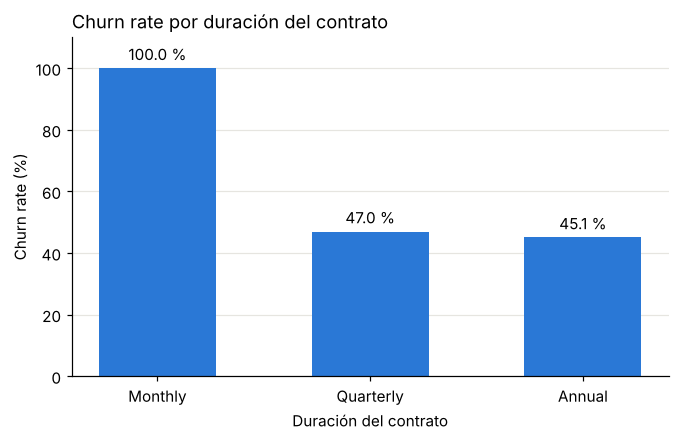

In [8]:
churn_por_contrato = churn_por("Contract Length")
churn_por_contrato.show()

barras_churn(churn_por_contrato.toPandas(), "Contract Length",
             "Churn rate por duración del contrato", "Duración del contrato", "churn_por_contrato.png",
             orden=["Monthly", "Quarterly", "Annual"])

### Interpretación desde el punto de vista de negocio
Los contratos más largos aportan estabilidad: los clientes anuales y trimestrales se van bastante menos (45–47 %).

El dato llamativo es que **el 100 % de los 1.984 clientes con contrato mensual ha hecho churn**. En la realidad sería extraño que
no quedara ni un solo cliente mensual; es otra señal de que el dataset es sintético. Para el modelo significa que la variable
`Contract Length` funciona casi como una regla determinista: cualquier cliente mensual es churn seguro. En el apartado 5 se comprueba si
el modelo sigue funcionando sin esta variable.

# 2. Análisis descriptivo
Resumen de las principales variables numéricas (media, desviación estándar, mínimo y máximo).

In [9]:
numeric_cols = ["Age", "Tenure", "Usage Frequency", "Support Calls",
                "Payment Delay", "Total Spend", "Last Interaction"]

df.select(numeric_cols).describe().show()

+-------+------------------+-----------------+-----------------+------------------+-----------------+------------------+-----------------+
|summary|               Age|           Tenure|  Usage Frequency|     Support Calls|    Payment Delay|       Total Spend| Last Interaction|
+-------+------------------+-----------------+-----------------+------------------+-----------------+------------------+-----------------+
|  count|             10000|            10000|            10000|             10000|            10000|             10000|            10000|
|   mean|           39.2613|          30.9536|          15.7726|            3.5932|          13.0305| 633.3173110000018|          14.4916|
| stddev|12.492486883437296|17.13792338300609|8.631357904404563|3.0796529327537288|8.261863929499139|240.47176902802795|8.621076599600162|
|    min|              18.0|              1.0|              1.0|               0.0|              0.0|             100.0|              1.0|
|    max|              65.0

### Conclusiones
* **Edad:** media de 39 años con una desviación de 12 (rango 18–65). La base de clientes es diversa en edad.
* **Antigüedad (Tenure):** media de 31 meses con una desviación alta (17); conviven clientes nuevos y antiguos.
* **Frecuencia de uso:** media de 15,8 con una desviación de 8,6 (el dataset no especifica la unidad). Hay clientes con un uso
  intensivo y otros que casi no usan el servicio.
* **Llamadas a soporte:** entre 3 y 4 de media, con una desviación de 3 (rango 0–10). Muchos clientes apenas llaman y otros lo hacen
  a menudo, posiblemente por problemas o insatisfacción.
* **Retraso en el pago:** 13 días de media (rango 0–30). Una parte importante de los clientes acumula retrasos.
* **Gasto total:** media de 633 unidades monetarias con una desviación de 240 (rango 100–1.000).
* **Última interacción:** de media hace unos 14 días; lo habitual es que pasen semanas sin contacto con la compañía.

### Perfil del cliente que abandona frente al que se queda

In [10]:
perfil = (df.groupBy("Churn_YesNo")
            .agg(*[F.round(F.avg(c), 1).alias(c) for c in numeric_cols])
            .orderBy("Churn_YesNo"))
perfil.toPandas().set_index("Churn_YesNo").T

Churn_YesNo,No,Yes
Age,36.0,41.7
Tenure,32.0,30.1
Usage Frequency,16.4,15.3
Support Calls,1.6,5.1
Payment Delay,10.0,15.3
Total Spend,749.9,544.4
Last Interaction,13.0,15.6


Comparar las medias de ambos grupos anticipa lo que el modelo va a aprender: los clientes que se van **llaman mucho más a soporte**,
**acumulan más retraso en los pagos**, **gastan menos** y son algo mayores. En cambio, la antigüedad y la frecuencia de uso son
prácticamente iguales en ambos grupos.

# 3. Análisis de correlación
Matriz de correlación (Pearson) entre las variables numéricas.

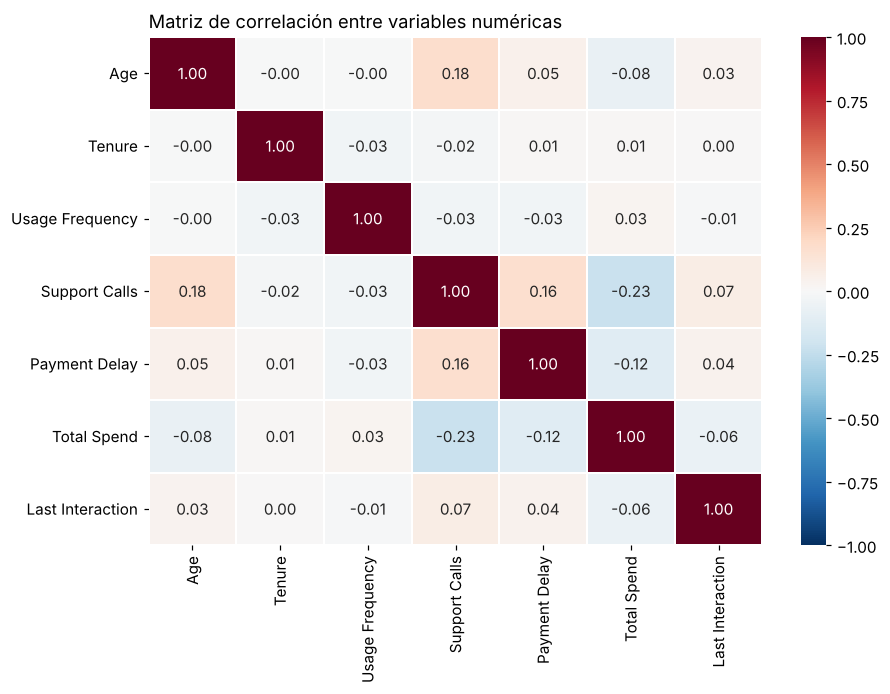

In [11]:
corr_df = pd.DataFrame(
    {c1: {c2: df.stat.corr(c1, c2) for c2 in numeric_cols} for c1 in numeric_cols}
)

plt.figure(figsize=(9, 6))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            center=0, linewidths=1, linecolor="white")
plt.title("Matriz de correlación entre variables numéricas", loc="left")
save_fig("matriz_correlacion.png")
plt.show()

## Relaciones entre variables
**Casi todas las correlaciones son muy bajas** (entre −0,08 y 0,08): edad, antigüedad, uso, gasto y última interacción apenas están
relacionadas entre sí de forma lineal.

Solo aparecen algunas relaciones **débiles**, todas alrededor de la variable *Support Calls*:

* **Llamadas a soporte – Gasto total (−0,23):** quien más llama a soporte tiende a gastar algo menos. Encaja con la idea de que una mala
  experiencia lleva a contratar menos servicios.
* **Llamadas a soporte – Edad (+0,18):** los clientes de más edad llaman algo más a soporte, quizá porque necesitan más asistencia.
* **Llamadas a soporte – Retraso en el pago (+0,16):** quien más llama también se retrasa algo más en los pagos, lo que podría
  apuntar a problemas de facturación o reclamaciones.
* **Retraso en el pago – Gasto total (−0,12):** relación negativa leve.

## Interpretación de negocio
Las correlaciones son débiles, así que no permiten sacar conclusiones fuertes sobre perfiles de cliente. Lo que sí sugieren es que
**las llamadas a soporte son el indicador que más se relaciona con el resto**: un cliente que llama mucho tiende a gastar menos y a
retrasarse más. Es la primera pista de que la experiencia en atención al cliente será clave en el churn.

# 4. Machine Learning
El problema de negocio consiste en predecir qué clientes tienen mayor probabilidad de abandonar la compañía. Perder un cliente
tiene un coste elevado: menores ingresos futuros, más gasto en captación y pérdida de cuota de mercado.

Un modelo predictivo permite identificar clientes de alto riesgo y activar estrategias de retención (descuentos, contacto proactivo,
mejora de la atención al cliente…) antes de que se vayan.

Se van a comparar dos modelos de clasificación: **Random Forest** y **Árbol de Decisión**.

### Preparación de las variables

In [12]:
categorical_cols = ["Gender", "Subscription Type", "Contract Length"]
label_col = "Churn_YesNo"
label_idx = label_col + "_idx"

def build_pipeline(model, categoricals, numerics):
    indexers = [StringIndexer(inputCol=c, outputCol=c + "_idx") for c in categoricals]
    label_indexer = StringIndexer(inputCol=label_col, outputCol=label_idx,
                                  stringOrderType="alphabetAsc")  # No -> 0, Yes -> 1
    encoders = [OneHotEncoder(inputCol=c + "_idx", outputCol=c + "_ohe") for c in categoricals]
    assembler = VectorAssembler(inputCols=numerics + [c + "_ohe" for c in categoricals],
                                outputCol="features")
    return Pipeline(stages=indexers + [label_indexer] + encoders + [assembler, model])

### División en entrenamiento y test
El 80 % de los clientes se usa para entrenar y ajustar el modelo, y el 20 % restante se reserva como **test**. El modelo nunca ve
estos clientes durante el entrenamiento, así que las métricas de test miden cómo se comportaría con clientes nuevos.

In [13]:
train_df, test_df = df.randomSplit([0.8, 0.2], seed=42)
train_df.cache(); test_df.cache()

print("Train:", train_df.count(), "clientes")
print("Test :", test_df.count(), "clientes")

Train: 8079 clientes


Test : 1921 clientes


## Random Forest: Grid Search + Cross Validation
Con **Grid Search** se definen varios valores para los hiperparámetros principales (número de árboles, profundidad máxima y número de bins)
y se prueban todas las combinaciones. Cada combinación se evalúa con **validación cruzada de 3 pliegues** sobre el conjunto de
entrenamiento, lo que da una estimación más robusta y reduce el riesgo de sobreajuste. La métrica de evaluación es el AUC-ROC.

In [14]:
evaluator = BinaryClassificationEvaluator(labelCol=label_idx, rawPredictionCol="rawPrediction",
                                          metricName="areaUnderROC")

rf = RandomForestClassifier(labelCol=label_idx, featuresCol="features", seed=42)
pipeline_rf = build_pipeline(rf, categorical_cols, numeric_cols)

paramGrid_rf = (ParamGridBuilder()
    .addGrid(rf.numTrees, [50, 100])
    .addGrid(rf.maxDepth, [5, 10])
    .addGrid(rf.maxBins, [32, 64])
    .build())

cv_rf = CrossValidator(estimator=pipeline_rf, estimatorParamMaps=paramGrid_rf,
                       evaluator=evaluator, numFolds=3, parallelism=2, seed=42)

cv_model_rf = cv_rf.fit(train_df)
best_model = cv_model_rf.bestModel
best_rf = best_model.stages[-1]
print("Mejores hiperparámetros:",
      f"numTrees={best_rf.getNumTrees}, maxDepth={best_rf.getMaxDepth()}, maxBins={best_rf.getMaxBins()}")

pred_train = best_model.transform(train_df)
pred_test = best_model.transform(test_df)

Mejores hiperparámetros: numTrees=100, maxDepth=10, maxBins=32


## Árbol de Decisión: Grid Search + Cross Validation

In [15]:
dt = DecisionTreeClassifier(labelCol=label_idx, featuresCol="features", seed=42)
pipeline_dt = build_pipeline(dt, categorical_cols, numeric_cols)

paramGrid_dt = (ParamGridBuilder()
    .addGrid(dt.maxDepth, [3, 5, 10])
    .addGrid(dt.maxBins, [32, 64])
    .addGrid(dt.minInstancesPerNode, [1, 5, 10])
    .build())

cv_dt = CrossValidator(estimator=pipeline_dt, estimatorParamMaps=paramGrid_dt,
                       evaluator=evaluator, numFolds=3, parallelism=2, seed=42)

best_model_dt = cv_dt.fit(train_df).bestModel
pred_dt_train = best_model_dt.transform(train_df)
pred_dt_test = best_model_dt.transform(test_df)

## Métricas de los modelos
Además del **AUC-ROC** (capacidad de separar a los clientes que se van de los que se quedan) se calculan, sobre el conjunto de test,
la **precisión** (de los clientes que el modelo marca como churn, cuántos lo son de verdad) y el **recall** (de los clientes que se
van, cuántos detecta el modelo).

In [16]:
def metricas(pred):
    cm = pred.groupBy(label_idx, "prediction").count().toPandas()
    get = lambda y, p: int(cm.loc[(cm[label_idx] == y) & (cm["prediction"] == p), "count"].sum())
    tp, fp, fn, tn = get(1, 1), get(0, 1), get(1, 0), get(0, 0)
    return {
        "AUC": evaluator.evaluate(pred),
        "Accuracy": (tp + tn) / (tp + tn + fp + fn),
        "Precision": tp / (tp + fp),
        "Recall": tp / (tp + fn),
        "FP": fp, "FN": fn,
    }

resumen = pd.DataFrame({
    "Random Forest · train": metricas(pred_train),
    "Random Forest · test": metricas(pred_test),
    "Árbol de Decisión · train": metricas(pred_dt_train),
    "Árbol de Decisión · test": metricas(pred_dt_test),
}).T
resumen.style.format({"AUC": "{:.4f}", "Accuracy": "{:.4f}", "Precision": "{:.4f}",
                      "Recall": "{:.4f}", "FP": "{:.0f}", "FN": "{:.0f}"})

,AUC,Accuracy,Precision,Recall,FP,FN
Random Forest · train,1.0000,0.9931,1.0000,0.9878,0,56
Random Forest · test,0.9990,0.9912,1.0000,0.9844,0,17
Árbol de Decisión · train,0.9948,0.9959,0.9998,0.9930,1,32
Árbol de Decisión · test,0.9909,0.9906,0.9981,0.9853,2,16


### Curvas ROC en test

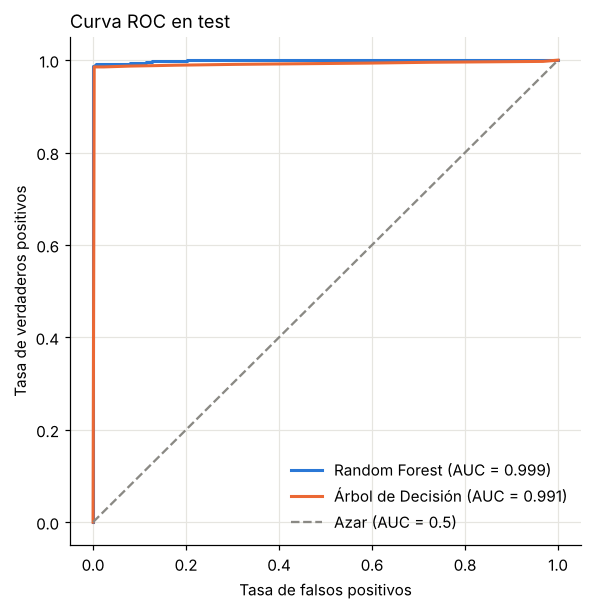

In [17]:
get_p1 = F.udf(lambda v: float(v[1]), DoubleType())  # probabilidad de la clase 1 (churn)

def roc_points(pred):
    pdf = pred.select(F.col(label_idx).cast("double").alias("label"),
                      get_p1("probability").alias("score")).toPandas()
    fpr, tpr, _ = roc_curve(pdf["label"], pdf["score"])
    return fpr, tpr, auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(6, 6))
for pred, nombre, color in [(pred_test, "Random Forest", BLUE), (pred_dt_test, "Árbol de Decisión", ORANGE)]:
    fpr, tpr, roc_auc = roc_points(pred)
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{nombre} (AUC = {roc_auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color=GREY, lw=1.5, label="Azar (AUC = 0.5)")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos")
ax.set_title("Curva ROC en test", loc="left")
ax.grid(True, axis="both")
ax.legend(loc="lower right", frameon=False)
save_fig("curva_roc_test.png")
plt.show()

### Matriz de confusión del Random Forest en test

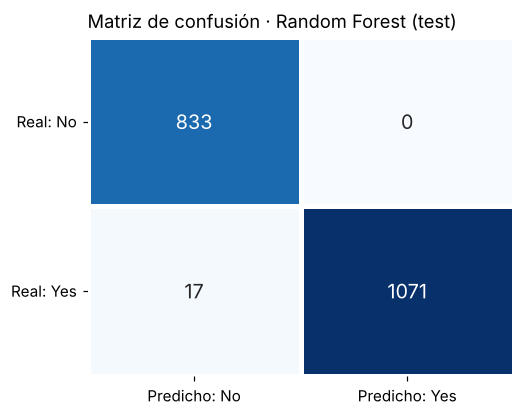

,Predicho: No,Predicho: Yes
Real: No,833,0
Real: Yes,17,1071


In [18]:
cm = (pred_test.groupBy(label_col, "prediction").count().toPandas()
      .pivot(index=label_col, columns="prediction", values="count").fillna(0).astype(int))
cm.columns = ["Predicho: No", "Predicho: Yes"]
cm.index = ["Real: No", "Real: Yes"]

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=2, linecolor="white",
            annot_kws={"size": 13})
plt.title("Matriz de confusión · Random Forest (test)", loc="left")
plt.yticks(rotation=0)
save_fig("matriz_confusion_rf.png")
plt.show()
cm

In [19]:
m = metricas(pred_test)
print(f"Clientes en test: {test_df.count()}")
print(f"Falsos positivos (se quedan pero el modelo predice churn): {m['FP']}")
print(f"Falsos negativos (se van pero el modelo no lo detecta):     {m['FN']}")

Clientes en test: 1921
Falsos positivos (se quedan pero el modelo predice churn): 0
Falsos negativos (se van pero el modelo no lo detecta):     17


### Interpretación
Los dos modelos obtienen resultados muy altos y prácticamente iguales en entrenamiento y en test, así que **no hay sobreajuste**: el
modelo generaliza bien a clientes que no ha visto. El **Random Forest es el mejor de los dos** (AUC en test ≈ 0,999 frente a ≈ 0,99
del Árbol de Decisión), y es el que se usa en el resto del proyecto.

En la matriz de confusión, los errores que más importan a la empresa son los **falsos negativos**: clientes que se van sin que el modelo
avise, y a los que, por tanto, no se les aplica ninguna acción de retención. Los falsos positivos tienen un coste menor (una oferta de
retención a un cliente que se habría quedado igualmente).

Unos resultados tan cercanos a la perfección no serían realistas con datos reales de una operadora. Aquí se deben a que el dataset es
sintético y sus clases están muy bien separadas (por ejemplo, la regla de los contratos mensuales que se vio antes).

# 5. Prueba de robustez: modelo sin `Contract Length`
Como todos los clientes con contrato mensual hacen churn, cabe preguntarse si el modelo solo está aprendiendo esa regla. Para
comprobarlo, se entrena el mismo Random Forest (con la misma búsqueda de hiperparámetros) **sin la variable `Contract Length`**.

In [20]:
rf_nc = RandomForestClassifier(labelCol=label_idx, featuresCol="features", seed=42)
pipeline_nc = build_pipeline(rf_nc, ["Gender", "Subscription Type"], numeric_cols)
paramGrid_nc = (ParamGridBuilder()
    .addGrid(rf_nc.numTrees, [50, 100])
    .addGrid(rf_nc.maxDepth, [5, 10])
    .addGrid(rf_nc.maxBins, [32, 64])
    .build())
cv_nc = CrossValidator(estimator=pipeline_nc, estimatorParamMaps=paramGrid_nc,
                       evaluator=evaluator, numFolds=3, parallelism=2, seed=42)
pred_nc_test = cv_nc.fit(train_df).bestModel.transform(test_df)

pd.DataFrame({
    "Random Forest (todas las variables)": metricas(pred_test),
    "Random Forest (sin Contract Length)": metricas(pred_nc_test),
}).T.style.format({"AUC": "{:.4f}", "Accuracy": "{:.4f}", "Precision": "{:.4f}",
                   "Recall": "{:.4f}", "FP": "{:.0f}", "FN": "{:.0f}"})

,AUC,Accuracy,Precision,Recall,FP,FN
Random Forest (todas las variables),0.9990,0.9912,1.0000,0.9844,0,17
Random Forest (sin Contract Length),0.9864,0.9719,0.9981,0.9522,2,52


Sin la duración del contrato, el modelo **sigue rindiendo a un nivel muy alto**, con solo una pequeña caída. Esto indica que no depende
únicamente de la regla de los contratos mensuales: las llamadas a soporte, el gasto, el retraso en el pago y la edad ya permiten
separar bien a los clientes que abandonan.

# 6. Segmentación por nivel de riesgo
Para que la empresa pueda actuar, la probabilidad de churn de cada cliente se traduce en tres niveles:

| Probabilidad de churn | Nivel | Acción |
|---|---|---|
| < 0,40 | Sin riesgo | Ninguna |
| 0,40 – 0,75 | Riesgo medio | Seguimiento / contacto proactivo |
| ≥ 0,75 | Alto riesgo | Acción de retención inmediata |

La distribución se calcula sobre el **conjunto de test**, para que refleje cómo funcionaría el modelo con clientes nuevos.

In [21]:
def add_risk(pred):
    return (pred.withColumn("churn_probability", get_p1("probability"))
                .withColumn("risk_level",
                    F.when(F.col("churn_probability") < 0.40, "Sin riesgo")
                     .when(F.col("churn_probability") < 0.75, "Riesgo medio")
                     .otherwise("Alto riesgo")))

risk_test = add_risk(pred_test)
(risk_test.groupBy("risk_level")
          .agg(F.count("*").alias("clientes"),
               F.round(F.avg(F.when(F.col(label_col) == "Yes", 1).otherwise(0)) * 100, 1).alias("% churn real"))
          .orderBy("clientes", ascending=False)
          .show())

+------------+--------+------------+
|  risk_level|clientes|% churn real|
+------------+--------+------------+
| Alto riesgo|    1051|       100.0|
|  Sin riesgo|     845|         1.7|
|Riesgo medio|      25|        92.0|
+------------+--------+------------+



La columna *% churn real* confirma que los niveles tienen sentido: casi todos los clientes de *Alto riesgo* se han ido de verdad y casi
ninguno de los de *Sin riesgo*. El grupo de *Riesgo medio* es pequeño, porque el modelo suele estar muy seguro de sus predicciones.

## Exportación para Power BI
Para el dashboard se puntúa a **todos los clientes** con el modelo final. Hay que tener en cuenta que el 80 % de ellos se usaron para
entrenar, así que sus probabilidades son algo más optimistas que las de un cliente nuevo; la columna `Conjunto` indica si cada cliente
estaba en train o en test, para poder filtrar en el dashboard.

In [22]:
scored = add_risk(
    best_model.transform(train_df).withColumn("Conjunto", F.lit("train"))
    .unionByName(best_model.transform(test_df).withColumn("Conjunto", F.lit("test")))
)

tabla_powerbi = scored.select(
    F.col("CustomerID").cast("int").alias("CustomerID"),
    F.col(label_col).alias("Churn_Real"),
    F.col("prediction").cast("int").alias("Prediccion_Modelo"),
    F.round(F.col("churn_probability"), 3).alias("Probabilidad_Churn"),
    F.col("risk_level").alias("Nivel_Riesgo"),
    "Conjunto",
).orderBy("CustomerID")

tabla_pd = tabla_powerbi.toPandas()
tabla_pd.to_csv(OUTPUT_DIR / "predicciones_churn_powerbi.csv", index=False)
print("Exportado:", len(tabla_pd), "clientes ->", "output/predicciones_churn_powerbi.csv")
tabla_pd.head()

Exportado: 10000 clientes -> output/predicciones_churn_powerbi.csv


,CustomerID,Churn_Real,Prediccion_Modelo,Probabilidad_Churn,Nivel_Riesgo,Conjunto
0,185,No,0,0.022,Sin riesgo,train
1,187,Yes,1,1.000,Alto riesgo,train
2,223,Yes,1,0.756,Alto riesgo,test
3,328,Yes,1,0.846,Alto riesgo,train
4,348,Yes,1,1.000,Alto riesgo,train


## Buscador por ID de cliente
Permite consultar la situación de un cliente concreto.

In [23]:
def buscar_cliente(customer_id):
    return tabla_pd[tabla_pd["CustomerID"] == int(customer_id)]

buscar_cliente(250716)

,CustomerID,Churn_Real,Prediccion_Modelo,Probabilidad_Churn,Nivel_Riesgo,Conjunto
5543,250716,Yes,1,1.0,Alto riesgo,train


# 7. Importancia de las variables
El Random Forest asigna a cada variable una puntuación según cuánto contribuye a separar a los clientes que abandonan de los que se quedan.

In [24]:
# Recuperar los nombres de las variables tal como las ordena el VectorAssembler
indexer_models = {s.getInputCol(): s for s in best_model.stages if type(s).__name__ == "StringIndexerModel"}
ohe_models = {s.getInputCol(): s for s in best_model.stages if type(s).__name__ == "OneHotEncoderModel"}

categorical_feature_names = []
for c in categorical_cols:
    labels = indexer_models[c].labels
    n = len(labels) - 1 if ohe_models[c + "_idx"].getDropLast() else len(labels)
    categorical_feature_names += [f"{c}_{labels[j]}" for j in range(n)]

importance_df = (pd.DataFrame({
        "feature": numeric_cols + categorical_feature_names,
        "importance": best_rf.featureImportances.toArray(),
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True))
importance_df

,feature,importance
0,Support Calls,0.335231
1,Total Spend,0.216688
2,Age,0.145704
3,Payment Delay,0.138523
4,Contract Length_Quarterly,0.044612
5,Contract Length_Annual,0.040868
6,Gender_Male,0.035723
7,Last Interaction,0.035415
8,Tenure,0.003441
9,Usage Frequency,0.003048


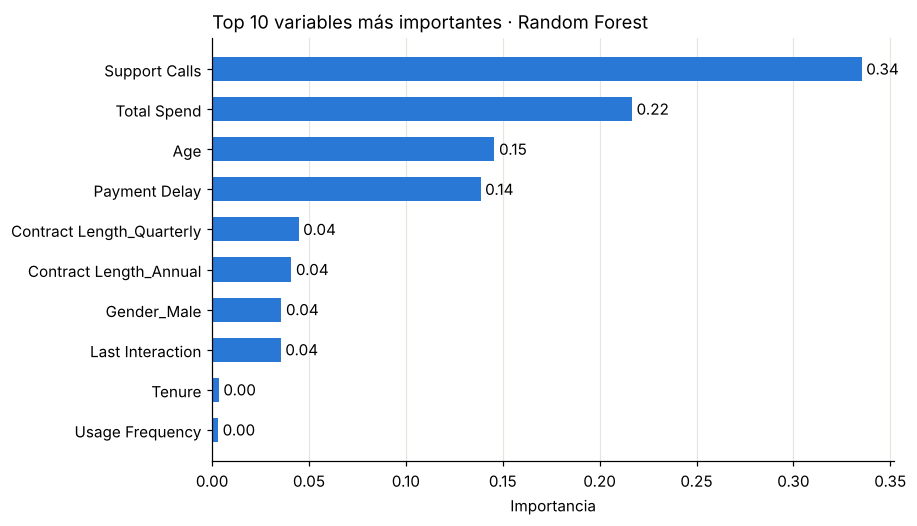

In [25]:
top = importance_df.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(top["feature"], top["importance"], color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{v:.2f}" for v in top["importance"]], padding=3)
ax.grid(True, axis="x"); ax.grid(False, axis="y")
ax.set_xlabel("Importancia")
ax.set_title("Top 10 variables más importantes · Random Forest", loc="left")
save_fig("importancia_variables.png")
plt.show()

# Conclusiones
* **Las llamadas a soporte son la variable más determinante.** Los clientes que abandonan llaman mucho más al servicio de atención al
  cliente: la calidad de la atención y la resolución de incidencias es la principal palanca para reducir el churn.
* **El gasto total y el retraso en el pago** son la segunda y tercera señal: los clientes que gastan menos y se retrasan más en los
  pagos tienen más riesgo de irse.
* **La edad** también influye: los clientes de más edad tienen algo más de probabilidad de abandonar. Más que excluirlos, esto sugiere
  revisar si la atención que reciben (que también son quienes más llaman a soporte) se adapta a sus necesidades.
* **El tipo de tarifa, la antigüedad y la frecuencia de uso apenas influyen** en el modelo.
* **La duración del contrato** es muy relevante en los datos (todos los clientes mensuales se van), pero el modelo sigue funcionando muy
  bien sin ella.

**Recomendaciones para Tokio Telecom:** usar el modelo para generar cada mes la lista de clientes de *Alto riesgo*, priorizar a los
que acumulan muchas llamadas a soporte o retrasos en el pago, e incentivar el paso de contratos mensuales a trimestrales o anuales.

**Limitaciones:** el dataset es sintético, con una tasa de churn y una separación entre clases poco realistas. Con datos reales se
esperarían métricas más bajas, y sería necesario validar el modelo con clientes de periodos posteriores al entrenamiento.

In [26]:
spark.stop()